## 1. Библиотеки и вычислительные ресурсы

In [1]:
from pathlib import Path
from time import perf_counter
from datetime import date
import gc
import json
import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer

DATA = Path("data")
DATA.mkdir(exist_ok=True)
torch.set_num_threads(2)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.35)
np.random.seed(42)
pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
print("Устройство:", DEVICE)
print("PyTorch:", torch.__version__)
print("Лимит потоков:", torch.get_num_threads())


Устройство: cuda
PyTorch: 2.7.1+cu126
Лимит потоков: 2


## 2. Сбор и очистка корпуса DataSphere

In [2]:
from concurrent.futures import ThreadPoolExecutor


def clean_markdown(raw):
    raw = raw[raw.find("\n# ") + 1:]
    raw = re.split(r"\n#{2,6} (?:Полезные ссылки|См\. также|Смотрите также)", raw)[0]
    raw = re.sub(r"!\[[^\]]*\]\([^\n]*?\)", "", raw)
    raw = re.sub(r"\[([^\]]+)\]\([^\s]+?\)", r"\1", raw)
    raw = re.sub(r"\{%.*?%\}|\{#[^}]+\}", "", raw, flags=re.S)
    raw = re.sub(r"^\s*```[^\n]*", "", raw, flags=re.M)
    raw = raw.replace("**", "").replace("`", "")
    return re.sub(r"\n\s*\n\s*\n", "\n\n", raw).strip()


def fetch_document(path):
    source = "https://docs.yandex.cloud/ru/ru/datasphere/" + path
    response = requests.get(source, timeout=45)
    if response.status_code != 200:
        return None
    text = clean_markdown(response.text)
    paragraphs = [p.strip() for p in text.split("\n\n") if p.strip()]
    prose = [p for p in paragraphs[1:] if not p.startswith(("#", "* ", "- "))]
    if len(" ".join(prose).split()) < 35:
        return None
    return {
        "doc_id": path.removesuffix(".md"),
        "title": paragraphs[0].lstrip("# "),
        "section": path.split("/")[0],
        "url": "https://yandex.cloud/ru/docs/datasphere/" + path.removesuffix(".md"),
        "text": text,
        "retrieved_at": date.today().isoformat(),
    }


corpus_path = DATA / "corpus.json"
if corpus_path.exists():
    documents = json.loads(corpus_path.read_text(encoding="utf-8"))
else:
    toc = requests.get(
        "https://raw.githubusercontent.com/yandex-cloud/docs/master/ru/datasphere/toc.yaml",
        timeout=45,
    )
    toc.raise_for_status()
    paths = sorted(set(re.findall(r"href:\s*([^\s]+\.md)", toc.text)))
    paths = [p for p in paths if p.startswith(("concepts/", "operations/", "tutorials/", "troubleshooting/", "security/"))]
    with ThreadPoolExecutor(max_workers=3) as pool:
        documents = [d for d in pool.map(fetch_document, paths) if d is not None]
    documents = pd.DataFrame(documents).drop_duplicates("text").to_dict("records")
    corpus_path.write_text(json.dumps(documents, ensure_ascii=False, indent=2), encoding="utf-8")

corpus = pd.DataFrame(documents)
corpus["words"] = corpus.text.str.split().str.len()
assert len(corpus) >= 100
print(f"Документов: {len(corpus)}, слов: {corpus.words.sum():,}")
display(corpus.groupby("section").agg(документов=("doc_id", "size"), медиана_слов=("words", "median")))
display(corpus[["title", "words", "url"]].head())


Документов: 121, слов: 69,389


,документов,медиана_слов
section,,
concepts,33,361.0
operations,62,167.5
security,1,1619.0
troubleshooting,1,152.0
tutorials,24,1286.5


,title,words,url
0,Управление расходами,239,https://yandex.cloud/ru/docs/datasphere/concepts/budget
1,Сообщества в DataSphere,318,https://yandex.cloud/ru/docs/datasphere/concepts/community
2,Конфигурации вычислительных ресурсов,379,https://yandex.cloud/ru/docs/datasphere/concepts/configurations
3,Вычисления на кластерах Apache Spark™,1187,https://yandex.cloud/ru/docs/datasphere/concepts/data-processing-operations
4,Шаблоны Yandex Data Processing,672,https://yandex.cloud/ru/docs/datasphere/concepts/data-processing-template


## 3. Разведочный анализ документов

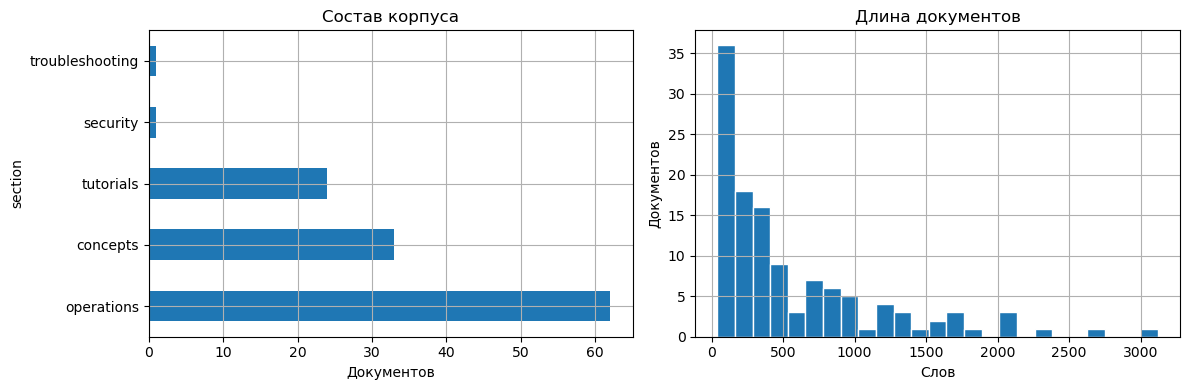

count     121.0
mean      573.0
std       613.0
min        41.0
50%       322.0
90%      1433.0
95%      1811.0
max      3121.0
Name: words, dtype: float64

,title,words
36,Создать сообщество,41
57,Удалить алиас,49
67,Аутентификация в DataSphere Jobs,50
83,Выбрать версию Python,51
68,Очистить вывод ячеек ноутбука,53


# Проверить загрузку GPU

В Yandex DataSphere доступны конфигурации вычислительных ресурсов с GPU.

Вы можете проверить работу, уровень загрузки и статистику потребления ресурсов GPU с помощью библиотеки TensorFlow и утилиты nvidia-smi.

## Перед началом работы 

Откройте проект DataSphere:

1. Выберите нужный проект в своем сообществе или на главной странице DataSphere во вкладке Недавние проекты.
1. Нажмите кнопку Открыть проект в JupyterLab и дождитесь окончания загрузки.
1. Откройте вкладку с ноутбуком.

## Проверить работу GPU 

### Проверить подключение с помощью TensorFlow 

1. Выберите необходимую конфигурацию GPU. В примере используется конфигурация g1.1.
1. В ячейке введите следующий код:

    import tensorflow as tf

    tf.config.list_physical_devices('GPU')

1. Выполните ячейку. Для этого нажмите значок .
1. В результате отобразятся все используемые в ноутбуке GPU.

### Проверить подключение с помощью nvidia-smi 

1. Выберите необходимую конфигурацию GPU. В примере использ

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
corpus.section.value_counts().plot.barh(ax=axes[0], title="Состав корпуса")
axes[0].set_xlabel("Документов")
axes[1].hist(corpus.words, bins=25, edgecolor="white")
axes[1].set(title="Длина документов", xlabel="Слов", ylabel="Документов")
plt.tight_layout()
plt.show()
display(corpus.words.describe(percentiles=[0.5, 0.9, 0.95]).round(0))
display(corpus.nsmallest(5, "words")[["title", "words"]])
print(corpus.loc[corpus.doc_id.eq("operations/projects/gpu-performance-check"), "text"].iloc[0][:2200])
print("Необработанные шаблоны:", corpus.text.str.contains(r"\{\{|\{%", regex=True).sum())


## 4. Поисковые запросы и разметка релевантности

In [4]:
queries = json.loads((DATA / "queries.json").read_text(encoding="utf-8"))
query_table = pd.DataFrame(queries)
assert len(queries) >= 20
assert all(q["relevant"] and set(q["relevant"]).issubset(set(corpus.doc_id)) for q in queries)
display(pd.crosstab(query_table.topic, query_table.difficulty))
display(query_table[["query_id", "query", "difficulty"]])
print("Разметка сверена AI-ассистентом с источниками; проверки человеком пока нет.")


difficulty,перефразированный,прямой,с условием
topic,,,
gpu,1,2,1
данные,1,1,2
доступ,1,1,2
задания,1,2,1
инференс,2,1,1
окружение,2,1,1


,query_id,query,difficulty
0,q01,Как записать загрузку GPU в файл во время обучения через nvidia-smi?,прямой
1,q02,"Почему одни машины в списке запускаются сразу, а другие приходится ждать?",перефразированный
2,q03,Можно ли перейти на другую вычислительную машину и сохранить уже созданные переменные ноутбука?,с условием
3,q04,Какие конфигурации предлагают GPU A100 и сколько у них видеопамяти?,прямой
4,q05,В ноутбуке не хватает библиотеки для графиков. Как добавить её и обновить окружение?,перефразированный
5,q06,Проекту нужна другая версия Python: как переключить её через готовый образ?,с условием
6,q07,Как создать и активировать собственный Docker-образ с нужными библиотеками для ноутбуков?,прямой
7,q08,"Как отправить скрипт на удалённое обучение, чтобы сервис сам собрал его зависимости?",перефразированный
8,q09,Хочу видеть бакет S3 как папку в JupyterLab и разрешить запись файлов. Как подключить его?,с условием
9,q10,Как использовать секрет в Python через переменную окружения?,прямой


Разметка сверена AI-ассистентом с источниками; проверки человеком пока нет.


## 5. Токенизаторы и общий размер входа

In [5]:
MODEL_IDS = {
    "MiniLM": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    "DistilUSE": "sentence-transformers/distiluse-base-multilingual-cased-v2",
    "E5-small": "intfloat/multilingual-e5-small",
}
TOKEN_LIMIT = 128
tokenizers = {name: AutoTokenizer.from_pretrained(model_id) for name, model_id in MODEL_IDS.items()}


def model_text(text, name, is_query=False):
    if name == "E5-small":
        return ("query: " if is_query else "passage: ") + text
    return text


def fits(text):
    return all(
        len(tokenizer.encode(model_text(text, name), truncation=False)) <= TOKEN_LIMIT
        for name, tokenizer in tokenizers.items()
    )


for name, tokenizer in tokenizers.items():
    lengths = [len(tokenizer.encode(model_text(q["query"], name, True))) for q in queries]
    assert max(lengths) <= TOKEN_LIMIT
    print(f"{name}: максимальная длина запроса {max(lengths)}, общий лимит {TOKEN_LIMIT}")


MiniLM: максимальная длина запроса 30, общий лимит 128
DistilUSE: максимальная длина запроса 37, общий лимит 128
E5-small: максимальная длина запроса 33, общий лимит 128


## 6. Окна с перекрытием и разбиение по абзацам

In [6]:
def split_window(text, title, overlap=0):
    words = re.findall(r"\S{1,40}", text)
    start = 0
    result = []
    while start < len(words):
        low, high = start + 1, min(start + TOKEN_LIMIT, len(words))
        end = start
        while low <= high:
            middle = (low + high) // 2
            if fits(title + "\n" + " ".join(words[start:middle])):
                end = middle
                low = middle + 1
            else:
                high = middle - 1
        assert end > start
        result.append(" ".join(words[start:end]))
        if end == len(words):
            break
        start = end - int((end - start) * overlap)
    return result


def split_paragraphs(text, title):
    result, current = [], ""
    for paragraph in re.split(r"\n\s*\n", text):
        paragraph = paragraph.strip()
        if not paragraph:
            continue
        candidate = (current + "\n\n" + paragraph).strip()
        if fits(title + "\n" + candidate):
            current = candidate
        else:
            if current:
                result.append(current)
            pieces = split_window(paragraph, title)
            result.extend(pieces[:-1])
            current = pieces[-1]
    if current:
        result.append(current)
    return result


chunks = {}
for strategy in ["окна", "абзацы"]:
    records = []
    for doc in documents:
        title = " ".join(doc["title"].split()[:10])
        body = doc["text"].split("\n", 1)[1].strip()
        pieces = split_window(body, title, 0.2) if strategy == "окна" else split_paragraphs(body, title)
        records.extend({"doc_id": doc["doc_id"], "text": title + "\n" + part} for part in pieces)
    chunks[strategy] = pd.DataFrame(records)

chunk_stats = []
for strategy, frame in chunks.items():
    row = {"стратегия": strategy, "чанков": len(frame), "документов": frame.doc_id.nunique()}
    for name, tokenizer in tokenizers.items():
        lengths = [len(tokenizer.encode(model_text(t, name))) for t in frame.text]
        assert max(lengths) <= TOKEN_LIMIT
        row[name + " max"] = max(lengths)
    chunk_stats.append(row)
display(pd.DataFrame(chunk_stats))
for strategy, frame in chunks.items():
    print("\n" + strategy.upper())
    print(frame.loc[frame.doc_id.eq("operations/projects/gpu-performance-check"), "text"].iloc[1])
del tokenizers, tokenizer
gc.collect()


Token indices sequence length is longer than the specified maximum sequence length for this model (631 > 512). Running this sequence through the model will result in indexing errors


,стратегия,чанков,документов,MiniLM max,DistilUSE max,E5-small max
0,окна,2003,121,126,128,128
1,абзацы,2010,121,126,128,128



ОКНА
Проверить загрузку GPU
странице DataSphere во вкладке Недавние проекты. 1. Нажмите кнопку Открыть проект в JupyterLab и дождитесь окончания загрузки. 1. Откройте вкладку с ноутбуком. ## Проверить работу GPU ### Проверить подключение с помощью TensorFlow 1. Выберите необходимую конфигурацию GPU. В примере используется конфигурация g1.1. 1. В ячейке введите следующий

АБЗАЦЫ
Проверить загрузку GPU
1. Выберите нужный проект в своем сообществе или на главной странице DataSphere во вкладке Недавние проекты. 1. Нажмите кнопку Открыть проект в JupyterLab и дождитесь окончания загрузки. 1. Откройте вкладку с ноутбуком.

## Проверить работу GPU

### Проверить подключение с помощью TensorFlow


0

## 7. Поиск по документам и метрики

In [7]:
def query_metrics(ranked_ids, relevant):
    hits = [i + 1 for i, doc_id in enumerate(ranked_ids[:5]) if doc_id in relevant]
    return {
        "MRR@5": 1 / hits[0] if hits else 0.0,
        "Recall@5": len(set(ranked_ids[:5]) & set(relevant)) / len(relevant),
    }


def rank_documents(scores, frame):
    rankings = []
    for row in scores:
        order = np.argsort(-row, kind="stable")
        top = frame.iloc[order].assign(score=row[order]).drop_duplicates("doc_id").head(5)
        rankings.append(top.to_dict("records"))
    return rankings


def evaluate(rankings):
    rows = []
    for query, ranking in zip(queries, rankings):
        rows.append({"query_id": query["query_id"], "difficulty": query["difficulty"],
                     **query_metrics([r["doc_id"] for r in ranking], query["relevant"])})
    return pd.DataFrame(rows)


def show_results(ranking):
    frame = pd.DataFrame(ranking).merge(corpus[["doc_id", "title", "url"]], on="doc_id")
    return frame[["title", "score", "url", "text"]].rename(columns={"text": "фрагмент"})


example = query_metrics(["wrong", "right", "other"], {"right", "missing"})
assert example == {"MRR@5": 0.5, "Recall@5": 0.5}
print("Проверка на примере:", example)
runs = {}


Проверка на примере: {'MRR@5': 0.5, 'Recall@5': 0.5}


## 8. Базовый поиск TF-IDF

In [8]:
tfidf_indexes = {}
for strategy, frame in chunks.items():
    start = perf_counter()
    vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True, dtype=np.float32)
    matrix = vectorizer.fit_transform(frame.text)
    index_seconds = perf_counter() - start
    start = perf_counter()
    query_vectors = vectorizer.transform(query_table["query"])
    rankings = rank_documents((query_vectors @ matrix.T).toarray(), frame)
    query_ms = (perf_counter() - start) * 1000 / len(queries)
    runs[("TF-IDF", strategy)] = {"rankings": rankings, "metrics": evaluate(rankings),
                                   "index_seconds": index_seconds, "query_ms": query_ms}
    tfidf_indexes[strategy] = (vectorizer, matrix)
    print(strategy, runs[("TF-IDF", strategy)]["metrics"][["MRR@5", "Recall@5"]].mean().round(3).to_dict())
display(show_results(runs[("TF-IDF", "окна")]["rankings"][1]))


окна {'MRR@5': 0.508, 'Recall@5': 0.514}


абзацы {'MRR@5': 0.454, 'Recall@5': 0.472}


,title,score,url,фрагмент
0,Как настроить проект для работы с облаком Yandex Cloud,0.143435,https://yandex.cloud/ru/docs/datasphere/tutorials/basics,"Как настроить проект для работы с облаком Yandex Cloud\nв команду, позволяют использовать общие ..."
1,О сервисе DataSphere,0.124281,https://yandex.cloud/ru/docs/datasphere/concepts/index,О сервисе DataSphere\nуже установлена среда разработки JupyterLab и пакеты для анализа данных и ...
2,Выбрать вычислительные ресурсы,0.109491,https://yandex.cloud/ru/docs/datasphere/operations/projects/control-compute-resources,Выбрать вычислительные ресурсы\nВы можете выбрать конфигурацию для ноутбука в момент первого зап...
3,Среда исполнения заданий,0.098768,https://yandex.cloud/ru/docs/datasphere/concepts/jobs/environment,"Среда исполнения заданий\nЗадания DataSphere Jobs выполняются на выделенных виртуальных машинах,..."
4,Создание сервера MLFlow для логирования экспериментов и артефактов,0.091260,https://yandex.cloud/ru/docs/datasphere/tutorials/mlflow-datasphere,Создание сервера MLFlow для логирования экспериментов и артефактов\nможно по ссылке http://<публ...


## 9. Семантический поиск multilingual MiniLM

In [9]:
from huggingface_hub.utils import disable_progress_bars

disable_progress_bars()


def run_dense(name):
    model = SentenceTransformer(
        MODEL_IDS[name], device=DEVICE,
        model_kwargs={"dtype": torch.float16 if DEVICE == "cuda" else torch.float32},
    )
    model.max_seq_length = TOKEN_LIMIT
    model.encode([model_text("проверка поиска", name, True)], show_progress_bar=False)
    print(name, "размерность:", model.get_sentence_embedding_dimension(),
          "параметров:", sum(p.numel() for p in model.parameters()))
    for strategy, frame in chunks.items():
        texts = [model_text(t, name) for t in frame.text]
        start = perf_counter()
        embeddings = model.encode(texts, batch_size=16, normalize_embeddings=True,
                                  show_progress_bar=False).astype(np.float32)
        index_seconds = perf_counter() - start
        start = perf_counter()
        query_vectors = model.encode(
            [model_text(q["query"], name, True) for q in queries],
            batch_size=16, normalize_embeddings=True, show_progress_bar=False,
        ).astype(np.float32)
        rankings = rank_documents(query_vectors @ embeddings.T, frame)
        query_ms = (perf_counter() - start) * 1000 / len(queries)
        runs[(name, strategy)] = {"rankings": rankings, "metrics": evaluate(rankings),
                                  "index_seconds": index_seconds, "query_ms": query_ms,
                                  "embeddings": embeddings}
        print(strategy, runs[(name, strategy)]["metrics"][["MRR@5", "Recall@5"]].mean().round(3).to_dict())
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


run_dense("MiniLM")
display(show_results(runs[("MiniLM", "окна")]["rankings"][1]))


MiniLM размерность: 384 параметров: 117653760


окна {'MRR@5': 0.531, 'Recall@5': 0.59}


абзацы {'MRR@5': 0.522, 'Recall@5': 0.604}


,title,score,url,фрагмент
0,Управление расходами,0.360051,https://yandex.cloud/ru/docs/datasphere/concepts/budget,"Управление расходами\nна количество юнитов в час, которое может использовать проект. Если цена з..."
1,Создать ноду,0.330493,https://yandex.cloud/ru/docs/datasphere/operations/deploy/node-create,Создать ноду\nИнтервал — интервал между проверками в секундах. * Неудачные проверки — допустимое...
2,Коннектор S3,0.293604,https://yandex.cloud/ru/docs/datasphere/concepts/s3-connector,Коннектор S3\nкаталогами с большим количеством файлов. Такой сценарий использования вызывает сущ...
3,Решение проблем,0.291454,https://yandex.cloud/ru/docs/datasphere/operations/projects/debugging-tools,"Решение проблем\nхранилища. * Остановить JupyterLab и ВМ — остановка всех вычислений, закрытие о..."
4,Проверки состояния и мониторинг,0.265993,https://yandex.cloud/ru/docs/datasphere/concepts/deploy/monitoring,Проверки состояния и мониторинг\nноде. Для проверок поддерживаются следующие настройки: * Таймау...


## 10. Семантический поиск multilingual DistilUSE

In [10]:
run_dense("DistilUSE")
display(show_results(runs[("DistilUSE", "абзацы")]["rankings"][19]))


DistilUSE размерность: 512 параметров: 135127808


окна {'MRR@5': 0.465, 'Recall@5': 0.604}


абзацы {'MRR@5': 0.556, 'Recall@5': 0.604}


,title,score,url,фрагмент
0,Управление расходами,0.386898,https://yandex.cloud/ru/docs/datasphere/concepts/budget,Управление расходами\nСуществует несколько способов контролировать расходы на вычисления:
1,Запуск вычислений по расписанию в DataSphere,0.346024,https://yandex.cloud/ru/docs/datasphere/tutorials/regular-launch,Запуск вычислений по расписанию в DataSphere\nЧтобы сократить расходы на использование сервиса D...
2,Развертывание сервиса из модели ONNX,0.340777,https://yandex.cloud/ru/docs/datasphere/tutorials/node-from-model,Развертывание сервиса из модели ONNX\n### Необходимые платные ресурсы\n\nВ стоимость развертыван...
3,Привязать платежный аккаунт,0.328859,https://yandex.cloud/ru/docs/datasphere/operations/community/link-ba,Привязать платежный аккаунт\nЕсли выбранный платежный аккаунт имеет задолженность или приостанов...
4,Задать ограничения для проекта,0.326260,https://yandex.cloud/ru/docs/datasphere/operations/projects/restrictions,"Задать ограничения для проекта\nтех пор, пока не выполнится одно из условий: * баланс станет мен..."


## 11. Семантический поиск multilingual E5-small

In [11]:
run_dense("E5-small")
display(show_results(runs[("E5-small", "абзацы")]["rankings"][19]))


E5-small размерность: 384 параметров: 117653760


окна {'MRR@5': 0.654, 'Recall@5': 0.708}


абзацы {'MRR@5': 0.595, 'Recall@5': 0.66}


,title,score,url,фрагмент
0,Запуск вычислений в DataSphere с помощью API,0.888574,https://yandex.cloud/ru/docs/datasphere/tutorials/batch-code-execution,"Запуск вычислений в DataSphere с помощью API\nЕсли созданные ресурсы вам больше не нужны, удалит..."
1,Задать ограничения для проекта,0.882363,https://yandex.cloud/ru/docs/datasphere/operations/projects/restrictions,"Задать ограничения для проекта\nтех пор, пока не выполнится одно из условий: * баланс станет мен..."
2,Запуск вычислений по расписанию в DataSphere,0.877615,https://yandex.cloud/ru/docs/datasphere/tutorials/regular-launch,Запуск вычислений по расписанию в DataSphere\n1. Выберите нужный проект в своем сообществе или н...
3,Выбрать вычислительные ресурсы,0.870626,https://yandex.cloud/ru/docs/datasphere/operations/projects/control-compute-resources,Выбрать вычислительные ресурсы\nИзменить конфигурацию вычислительных ресурсов с сохранением сост...
4,Решение проблем,0.868782,https://yandex.cloud/ru/docs/datasphere/operations/projects/debugging-tools,Решение проблем\n1. Выберите нужный проект в своем сообществе или на главной странице DataSphere...


## 12. Сравнение восьми вариантов и проверка выдачи

In [12]:
def comparison_table():
    rows = []
    for (name, strategy), result in runs.items():
        rows.append({"модель": name, "чанки": strategy,
                     **result["metrics"][["MRR@5", "Recall@5"]].mean().to_dict(),
                     "индекс, с": result["index_seconds"], "запрос, мс": result["query_ms"]})
    return pd.DataFrame(rows).sort_values(["MRR@5", "Recall@5", "запрос, мс"], ascending=[False, False, True])


display(comparison_table().round(3))
pool = []
for i, query in enumerate(queries):
    seen = set()
    candidates = []
    for result in runs.values():
        for item in result["rankings"][i]:
            if item["doc_id"] not in seen:
                candidates.append({"doc_id": item["doc_id"], "text": item["text"]})
                seen.add(item["doc_id"])
    pool.append({"query_id": query["query_id"], "query": query["query"], "candidates": candidates})
(DATA / "retrieval_pool.json").write_text(json.dumps(pool, ensure_ascii=False, indent=2), encoding="utf-8")
print("Пар запрос–документ в объединённой выдаче:", sum(len(q["candidates"]) for q in pool))


,модель,чанки,MRR@5,Recall@5,"индекс, с","запрос, мс"
6,E5-small,окна,0.654,0.708,39.496,11.779
7,E5-small,абзацы,0.595,0.660,36.545,7.950
5,DistilUSE,абзацы,0.556,0.604,74.028,13.556
2,MiniLM,окна,0.531,0.590,39.337,10.121
3,MiniLM,абзацы,0.522,0.604,35.749,6.575
0,TF-IDF,окна,0.508,0.514,0.863,1.500
4,DistilUSE,окна,0.465,0.604,77.282,13.076
1,TF-IDF,абзацы,0.454,0.472,0.746,1.821


Пар запрос–документ в объединённой выдаче: 392


## 13. Дополнительный эксперимент: больше контекста для E5

In [13]:
TOKEN_LIMIT = 256
tokenizers = {"E5-small": AutoTokenizer.from_pretrained(MODEL_IDS["E5-small"])}
records = []
for doc in documents:
    title = " ".join(doc["title"].split()[:10])
    body = doc["text"].split("\n", 1)[1].strip()
    records.extend({"doc_id": doc["doc_id"], "text": title + "\n" + part}
                   for part in split_paragraphs(body, title))
frame_256 = pd.DataFrame(records)
assert all(fits(t) for t in frame_256.text)
print("Чанков:", len(frame_256), "лимит E5:", TOKEN_LIMIT)
del tokenizers
gc.collect()

model = SentenceTransformer(MODEL_IDS["E5-small"], device=DEVICE,
                            model_kwargs={"dtype": torch.float16 if DEVICE == "cuda" else torch.float32})
model.max_seq_length = TOKEN_LIMIT
model.encode(["query: проверка поиска"], show_progress_bar=False)
start = perf_counter()
embeddings_256 = model.encode(["passage: " + t for t in frame_256.text], batch_size=16,
                              normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
index_seconds = perf_counter() - start
start = perf_counter()
query_vectors = model.encode(["query: " + q["query"] for q in queries], batch_size=16,
                              normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
rankings_256 = rank_documents(query_vectors @ embeddings_256.T, frame_256)
query_ms = (perf_counter() - start) * 1000 / len(queries)
chunks["абзацы 256"] = frame_256
runs[("E5-small", "абзацы 256")] = {"rankings": rankings_256, "metrics": evaluate(rankings_256),
    "index_seconds": index_seconds, "query_ms": query_ms, "embeddings": embeddings_256}
display(comparison_table().round(3))
del model
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()


Token indices sequence length is longer than the specified maximum sequence length for this model (672 > 512). Running this sequence through the model will result in indexing errors


Чанков: 755 лимит E5: 256


,модель,чанки,MRR@5,Recall@5,"индекс, с","запрос, мс"
8,E5-small,абзацы 256,0.667,0.667,30.060,7.763
6,E5-small,окна,0.654,0.708,39.496,11.779
7,E5-small,абзацы,0.595,0.660,36.545,7.950
5,DistilUSE,абзацы,0.556,0.604,74.028,13.556
2,MiniLM,окна,0.531,0.590,39.337,10.121
3,MiniLM,абзацы,0.522,0.604,35.749,6.575
0,TF-IDF,окна,0.508,0.514,0.863,1.500
4,DistilUSE,окна,0.465,0.604,77.282,13.076
1,TF-IDF,абзацы,0.454,0.472,0.746,1.821


## 14. Дополнение списка документов для проверки

In [14]:
new_candidates = []
for query_pool, ranking in zip(pool, rankings_256):
    seen = {item["doc_id"] for item in query_pool["candidates"]}
    for item in ranking:
        if item["doc_id"] not in seen:
            query_pool["candidates"].append({"doc_id": item["doc_id"], "text": item["text"]})
            new_candidates.append({"query_id": query_pool["query_id"], "doc_id": item["doc_id"]})
(DATA / "retrieval_pool.json").write_text(json.dumps(pool, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(new_candidates))


,query_id,doc_id
0,q02,concepts/data-processing-operations
1,q02,concepts/temporary-data-processing-clusters
2,q03,tutorials/yq-storage
3,q06,operations/projects/remote-connect
4,q06,operations/data/models
5,q08,tutorials/node-from-docker
6,q09,tutorials/s3-to-datasphere
7,q14,tutorials/mlflow-datasphere
8,q14,operations/data/dataset
9,q15,operations/projects/debugging-tools


## 15. Уточнение релевантности и итоговые метрики

In [15]:
review = json.loads((DATA / "relevance_review.json").read_text(encoding="utf-8"))
for change in review["changes"]:
    query = next(q for q in queries if q["query_id"] == change["query_id"])
    query["relevant"].update(change["add"])
    for doc_id in change["remove"]:
        query["relevant"].pop(doc_id, None)
assert all(q["relevant"] and set(q["relevant"]).issubset(set(corpus.doc_id)) for q in queries)
for result in runs.values():
    result["metrics"] = evaluate(result["rankings"])
summary = comparison_table()
display(summary.round(3))
summary.to_csv(DATA / "results.csv", index=False)
per_query = pd.concat([result["metrics"].assign(model=name, strategy=strategy)
                       for (name, strategy), result in runs.items()], ignore_index=True)
per_query.to_csv(DATA / "per_query_results.csv", index=False)
print("Добавлено соответствий:", sum(len(c["add"]) for c in review["changes"]))
print("Удалено соответствий:", sum(len(c["remove"]) for c in review["changes"]))
print("Запросы и поисковые выдачи не менялись; все метрики пересчитаны по одной разметке.")


,модель,чанки,MRR@5,Recall@5,"индекс, с","запрос, мс"
6,E5-small,окна,0.668,0.668,39.496,11.779
8,E5-small,абзацы 256,0.667,0.646,30.060,7.763
7,E5-small,абзацы,0.608,0.609,36.545,7.950
5,DistilUSE,абзацы,0.556,0.554,74.028,13.556
2,MiniLM,окна,0.529,0.519,39.337,10.121
3,MiniLM,абзацы,0.522,0.550,35.749,6.575
0,TF-IDF,окна,0.520,0.510,0.863,1.500
1,TF-IDF,абзацы,0.488,0.472,0.746,1.821
4,DistilUSE,окна,0.465,0.589,77.282,13.076


Добавлено соответствий: 12
Удалено соответствий: 2
Запросы и поисковые выдачи не менялись; все метрики пересчитаны по одной разметке.


## 16. Сравнение качества и сложности запросов

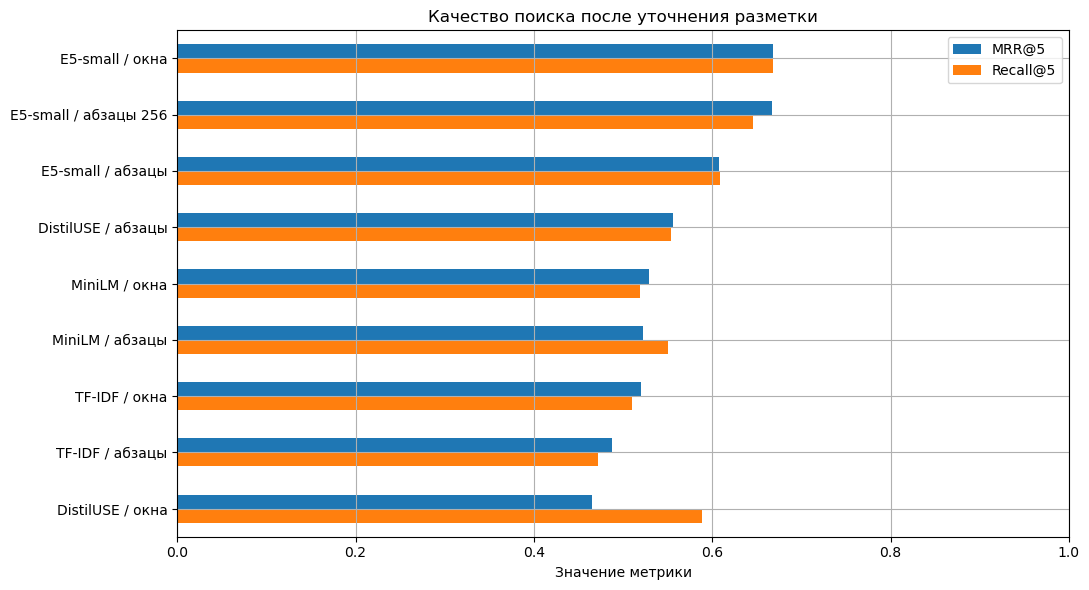

difficulty            перефразированный  прямой  с условием
model     strategy                                         
DistilUSE абзацы                  0.292   0.750       0.625
          окна                    0.219   0.688       0.490
E5-small  абзацы                  0.479   0.844       0.500
          абзацы 256              0.562   0.875       0.562
          окна                    0.442   1.000       0.562
MiniLM    абзацы                  0.406   0.719       0.442
          окна                    0.375   0.775       0.438
TF-IDF    абзацы                  0.292   0.646       0.525
          окна                    0.260   0.875       0.425

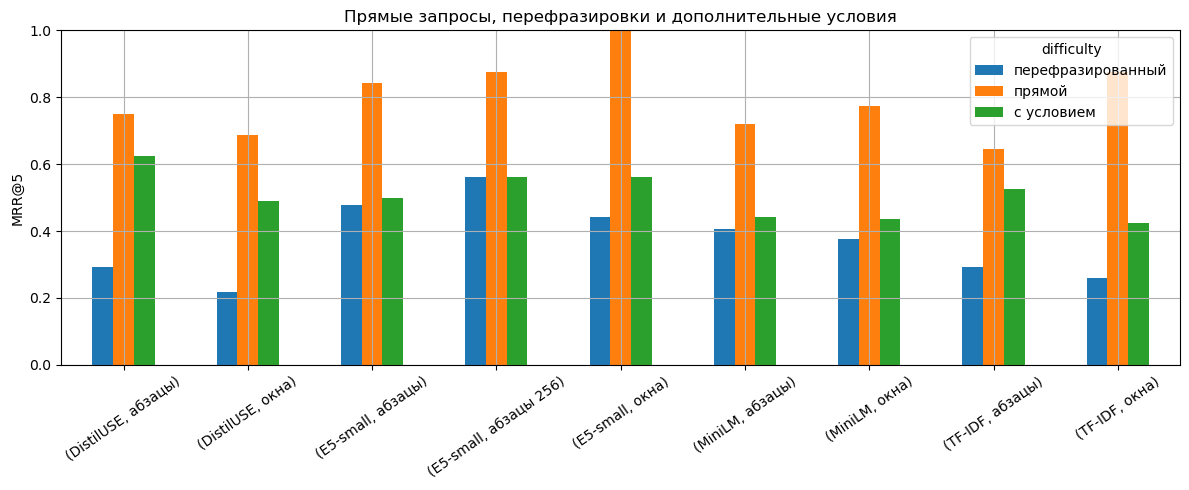

In [16]:
plot_table = summary.set_index(summary["модель"] + " / " + summary["чанки"])
ax = plot_table[["MRR@5", "Recall@5"]].plot.barh(figsize=(11, 6), xlim=(0, 1))
ax.invert_yaxis()
ax.set(xlabel="Значение метрики", ylabel="", title="Качество поиска после уточнения разметки")
plt.tight_layout()
plt.show()
by_difficulty = per_query.pivot_table(index=["model", "strategy"], columns="difficulty",
                                      values="MRR@5", aggfunc="mean")
display(by_difficulty.round(3))
by_difficulty.plot.bar(figsize=(12, 5), ylim=(0, 1), rot=35)
plt.ylabel("MRR@5")
plt.xlabel("")
plt.title("Прямые запросы, перефразировки и дополнительные условия")
plt.tight_layout()
plt.show()


## 17. Где семантический поиск выигрывает и ошибается

In [17]:
best_row = summary.iloc[0]
best_key = (best_row["модель"], best_row["чанки"])
baseline_row = summary.loc[summary["модель"].eq("TF-IDF")].iloc[0]
baseline_key = ("TF-IDF", baseline_row["чанки"])
comparison = query_table[["query_id", "query", "difficulty"]].copy()
comparison["TF-IDF RR@5"] = runs[baseline_key]["metrics"]["MRR@5"].to_numpy()
comparison["E5 RR@5"] = runs[best_key]["metrics"]["MRR@5"].to_numpy()
comparison["разница"] = comparison["E5 RR@5"] - comparison["TF-IDF RR@5"]
wins = comparison.loc[comparison["разница"] > 0].nlargest(3, "разница")
losses = comparison.loc[comparison["разница"] < 0].nsmallest(3, "разница")
print("Выбранный вариант:", best_key)
print("Выигрыши относительно TF-IDF")
display(wins)
print("Проигрыши относительно TF-IDF")
display(losses)
print("Запросы без релевантного документа в топ-5 выбранной модели")
display(comparison.loc[comparison["E5 RR@5"].eq(0)])
comparison.to_csv(DATA / "query_comparison.csv", index=False)
for i in pd.concat([wins, losses]).index:
    print("\n" + queries[i]["query_id"] + ": " + queries[i]["query"])
    rows = []
    for key in [baseline_key, best_key]:
        for rank, result in enumerate(runs[key]["rankings"][i][:3], 1):
            rows.append({"метод": key[0], "позиция": rank,
                         "документ": corpus.set_index("doc_id").loc[result["doc_id"], "title"],
                         "релевантен": result["doc_id"] in queries[i]["relevant"]})
    display(pd.DataFrame(rows))


Выбранный вариант: ('E5-small', 'окна')
Выигрыши относительно TF-IDF


,query_id,query,difficulty,TF-IDF RR@5,E5 RR@5,разница
20,q21,"Нужно пригласить коллегу в проект, но его нет в списке доступных участников. Что делать?",с условием,0.0,1.0,1.0
21,q22,"Как добавить в свой проект ресурс, уже опубликованный в сообществе?",прямой,0.0,1.0,1.0
10,q11,В проекте закончилось место для файлов. Где увеличить доступный объём диска?,перефразированный,0.0,0.5,0.5


Проигрыши относительно TF-IDF


,query_id,query,difficulty,TF-IDF RR@5,E5 RR@5,разница
17,q18,"Хочу постепенно направлять трафик на новую версию модели, не меняя адрес сервиса для пользователей.",с условием,0.20,0.000000,-0.200000
13,q14,Обучение завершилось в облаке. Как забрать полученные файлы на свой компьютер?,перефразированный,0.50,0.333333,-0.166667
7,q08,"Как отправить скрипт на удалённое обучение, чтобы сервис сам собрал его зависимости?",перефразированный,0.25,0.200000,-0.050000


Запросы без релевантного документа в топ-5 выбранной модели


...

,метод,позиция,документ,релевантен
0,TF-IDF,1,Отправить запрос в алиас,False
1,TF-IDF,2,Добавить пользователя в сообщество,False
2,TF-IDF,3,Как перенести работу в новую версию DataSphere,False
3,E5-small,1,Добавить пользователя в проект,False
4,E5-small,2,Добавить пользователя в сообщество,False
5,E5-small,3,Хранение приватных данных,False



q14: Обучение завершилось в облаке. Как забрать полученные файлы на свой компьютер?


,метод,позиция,документ,релевантен
0,TF-IDF,1,Развертывание gRPC-сервиса на основе Docker-образа,False
1,TF-IDF,2,DataSphere Jobs,True
2,TF-IDF,3,Развертывание сервиса на основе Docker-образа с FastAPI,False
3,E5-small,1,Использование данных из Yandex Object Storage для обучения модели в DataSphere,False
4,E5-small,2,Хранение приватных данных,False
5,E5-small,3,Экспортировать проект,True



q08: Как отправить скрипт на удалённое обучение, чтобы сервис сам собрал его зависимости?


,метод,позиция,документ,релевантен
0,TF-IDF,1,Настроить окружение для развертывания самостоятельного сервиса,False
1,TF-IDF,2,Установить зависимости,False
2,TF-IDF,3,Создать пустой проект,False
3,E5-small,1,Установить зависимости,False
4,E5-small,2,Специальные условия для образовательных учреждений,False
5,E5-small,3,Работа с секретами,False


## 18. Поиск по своему запросу

In [18]:
search_query = "Как подключиться к облачному ноутбуку из Visual Studio Code?"
name, strategy = best_key
frame = chunks[strategy]
if name == "TF-IDF":
    vectorizer, matrix = tfidf_indexes[strategy]
    scores = (vectorizer.transform([search_query]) @ matrix.T).toarray()
else:
    model = SentenceTransformer(MODEL_IDS[name], device=DEVICE, local_files_only=True,
                                model_kwargs={"dtype": torch.float16 if DEVICE == "cuda" else torch.float32})
    model.max_seq_length = 256 if strategy == "абзацы 256" else 128
    query_vector = model.encode([model_text(search_query, name, True)], normalize_embeddings=True,
                                show_progress_bar=False).astype(np.float32)
    scores = query_vector @ runs[best_key]["embeddings"].T
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
ranking = rank_documents(scores, frame)[0]
assert len({r["doc_id"] for r in ranking}) == 5
print(search_query)
print("Модель и разбиение:", best_key)
with pd.option_context("display.max_colwidth", 160):
    display(show_results(ranking))


Как подключиться к облачному ноутбуку из Visual Studio Code?
Модель и разбиение: ('E5-small', 'окна')


,title,score,url,фрагмент
0,Подключение к JupyterLab проекта из локальной IDE,0.873126,https://yandex.cloud/ru/docs/datasphere/operations/projects/remote-connect,Подключение к JupyterLab проекта из локальной IDE\n1. Нажмите Копировать ссылку. 1. Откройте файл формата ipynb в Visual Studio Code. 1. В правом верхнем уг...
1,Подключение к S3 с помощью библиотеки boto3,0.867726,https://yandex.cloud/ru/docs/datasphere/operations/data/connect-to-s3,Подключение к S3 с помощью библиотеки boto3\nс большим количеством файлов. Такой сценарий использования вызывает существенное снижение производительности хр...
2,Подключение к хранилищу S3,0.867656,https://yandex.cloud/ru/docs/datasphere/operations/data/s3-connectors,Подключение к хранилищу S3\nВы можете управлять подключением к объектному хранилищу S3 в интерфейсе DataSphere на странице проекта с помощью ресурса Коннект...
3,Работа с заданиями из Visual Studio Code,0.858817,https://yandex.cloud/ru/docs/datasphere/operations/projects/jobs-toolkit,Работа с заданиями из Visual Studio Code\nостанавливать задание. * Attach — подключаться к заданию. * Copy job ID — копировать идентификатор задания. * Open...
4,Подключение к Яндекс Диску,0.851504,https://yandex.cloud/ru/docs/datasphere/operations/data/connect-to-ya-disk,Подключение к Яндекс Диску\nво вкладке Недавние проекты. 1. Нажмите кнопку Открыть проект в JupyterLab и дождитесь окончания загрузки. 1. Откройте вкладку с...
